### Importing

This cell imports the libraries and scikit-learn tools needed for data handling, preprocessing, modeling, and evaluation.


In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pickle

This cell loads the heart disease dataset and displays a random sample of rows.


In [64]:
df = pd.read_csv("heart_disease_dataset.csv")#reading dataset
df.sample(5)#this prints random values

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
428,78,Female,318,133,73,Current,Moderate,1,Yes,Yes,No,2,168,No,Asymptomatic,1
780,64,Male,232,144,79,Former,Heavy,5,No,No,Yes,7,104,No,Asymptomatic,1
672,64,Male,218,114,90,Current,Moderate,4,No,Yes,No,3,147,Yes,Asymptomatic,1
6,64,Female,211,105,86,Former,Heavy,8,Yes,Yes,Yes,2,120,No,Typical Angina,1
188,53,Male,265,93,82,Current,Heavy,2,No,No,No,7,113,Yes,Asymptomatic,1


In [65]:
df[df.columns[2]].min()

np.int64(150)

In [66]:
df[df.columns[2]].max()

np.int64(349)

This cell checks the data type of each column in the dataset.


In [67]:
df.columns

Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='str')

In [68]:
df.dtypes#this prints datatypes of each column

Age                        int64
Gender                       str
Cholesterol                int64
Blood Pressure             int64
Heart Rate                 int64
Smoking                      str
Alcohol Intake               str
Exercise Hours             int64
Family History               str
Diabetes                     str
Obesity                      str
Stress Level               int64
Blood Sugar                int64
Exercise Induced Angina      str
Chest Pain Type              str
Heart Disease              int64
dtype: object

This cell counts missing values in each column.


In [69]:
df.isnull().sum()#it checks for any null values

Age                          0
Gender                       0
Cholesterol                  0
Blood Pressure               0
Heart Rate                   0
Smoking                      0
Alcohol Intake             340
Exercise Hours               0
Family History               0
Diabetes                     0
Obesity                      0
Stress Level                 0
Blood Sugar                  0
Exercise Induced Angina      0
Chest Pain Type              0
Heart Disease                0
dtype: int64

This cell checks whether the dataset contains duplicate rows.


In [70]:
df.duplicated().any()#it shows the duplicated values

np.False_

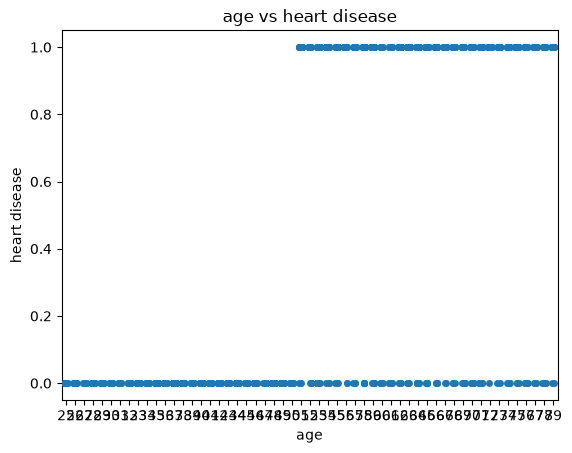

In [71]:
sns.stripplot(data = df , x = "Age" , y = "Heart Disease" , jitter = 0.2)
plt.xlabel("age")
plt.ylabel("heart disease")
plt.title("age vs heart disease")
plt.show()

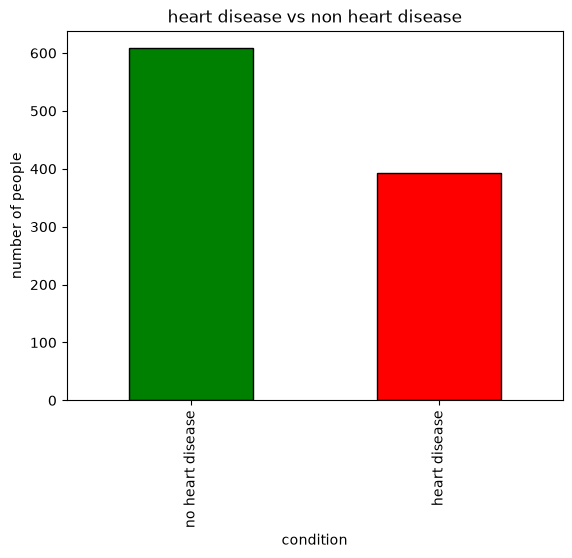

In [72]:
counts = df["Heart Disease"].value_counts().reindex([0,1]).fillna(0)
counts.index = ["no heart disease" , "heart disease"]
counts.plot(kind  = "bar" , color = ["green" , "red"], edgecolor = "black")
plt.xlabel("condition")
plt.ylabel("number of people")
plt.title("heart disease vs non heart disease")
plt.show()

This cell separates features from the target and splits the data into training and testing sets.


In [73]:
#seperating the input and output columns
X = df.drop(columns = "Heart Disease")
Y = df["Heart Disease"]
X_train , X_test , Y_train , Y_test = train_test_split(X , Y , test_size=0.3 , random_state=42, stratify=Y)

### Preprocessing

This cell identifies numerical and categorical columns from the training data.


In [74]:
numerical_columns = X_train.select_dtypes(include = ["number"]).columns#this will get all the numerical columns
categorical_columns = X_train.select_dtypes(exclude = ["number"]).columns#this will select the categoriacal columns


This cell builds a preprocessing pipeline for numerical columns using mean imputation and scaling.


In [75]:
# i will make numeric pipeline here
simple_imputer_num= SimpleImputer(strategy  = "mean")
scaler = StandardScaler()
numerical_pipeline = Pipeline([
    ("imputer" , simple_imputer_num),
    ("scaler"  , scaler)
])

This cell builds a preprocessing pipeline for categorical columns using mode imputation and one-hot encoding.


In [76]:
#i will make a categorical pipeline here
simple_imputer_cat = SimpleImputer(strategy= "most_frequent")
one_hot_encoder = OneHotEncoder(sparse_output = False , handle_unknown = "ignore")
categorical_pipeline = Pipeline([
    ("imputer" , simple_imputer_cat),
    ("one_hot_encoder" , one_hot_encoder)
])


This cell combines the numerical and categorical preprocessing pipelines into one column transformer.


In [77]:
#it makes the entire dataset from the transformed columns
processed_data = ColumnTransformer([
    ("numerical_pipeline" , numerical_pipeline , numerical_columns),
    ("categorical_pipeline" , categorical_pipeline , categorical_columns)
])

### Create Logistic Regression, Decision Tree, and Random Forest models

In [78]:
# Compare Logistic Regression, Decision Tree, and Random Forest.
logistic_pipeline = Pipeline([
    ("preprocessed_data", processed_data),
    ("model", LogisticRegression(max_iter=1000))
])

decision_tree_pipeline = Pipeline([
    ("preprocessed_data", processed_data),
    ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))
])

random_forest_pipeline = Pipeline([
    ("preprocessed_data", processed_data),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

### Train all three models

In [79]:
# Fit all pipelines on the training data.
logistic_pipeline.fit(X_train, Y_train)
decision_tree_pipeline.fit(X_train, Y_train)
random_forest_pipeline.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessed_data', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Cholesterol',...,'Blood Sugar','Exercise Induced Angina', 'Chest Pain Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical_pipeline', ...), ('categorical_pipeline', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

## Comparing model performance

In [80]:
logistic_predictions = logistic_pipeline.predict(X_test)
decision_tree_predictions = decision_tree_pipeline.predict(X_test)
random_forest_predictions = random_forest_pipeline.predict(X_test)

## Evaluate both models

This cell compares all three models with stratified 5-fold cross-validation on the training data and reports accuracy, confusion matrices, and classification reports on the same held-out test data.

In [81]:
for model_name, predictions in [
    ("Logistic Regression", logistic_predictions),
    ("Random Forest", random_forest_predictions),
    ("Decision Tree", decision_tree_predictions)
]:
    print(f"\n{model_name}")
    print("Accuracy:",
          f"{accuracy_score(Y_test, predictions) * 100:.2f}%")

    print(classification_report(
        Y_test, predictions, zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(Y_test, predictions))


Logistic Regression
Accuracy: 88.33%
              precision    recall  f1-score   support

           0       0.88      0.93      0.91       182
           1       0.88      0.81      0.85       118

    accuracy                           0.88       300
   macro avg       0.88      0.87      0.88       300
weighted avg       0.88      0.88      0.88       300

Confusion Matrix:
[[169  13]
 [ 22  96]]

Random Forest
Accuracy: 99.67%
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       182
           1       1.00      0.99      1.00       118

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300

Confusion Matrix:
[[182   0]
 [  1 117]]

Decision Tree
Accuracy: 100.00%
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       182
           1       1.00      1.00      1.00       11

## Deploying the Random Forest model

The Random Forest pipeline is selected for the app and saved to `disease_prediction.pkl`. The next cell refits it on all available data after evaluation. To deploy Logistic Regression instead, change `pipeline` to `logistic_pipeline`.

In [ ]:
# Refit the selected model on all available data for deployment.
pipeline = logistic_pipeline
pipeline.fit(X, Y)

with open("disease_prediction.pkl", "wb") as file:
    pickle.dump(pipeline, file)

### Decision Tree Using Age and Cholesterol

This cell trains a decision tree using only the `Age` and `Cholesterol` features. It makes a stratified 80/20 train-test split and prints accuracy on the held-out test data.

In [84]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

X_small = df[["Age", "Cholesterol"]]
y = df["Heart Disease"]  # use your actual target column

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_small, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_s, y_train_s)

predictions = dt.predict(X_test_s)

print("Accuracy:", accuracy_score(y_test_s, predictions))

Accuracy: 1.0
